# ROC & AUC — Diffusion-Dynamics Fingerprint

A C2 correctness model built from **how the diffusion counterfactual moved**, not from what
it looks like. No CF attributes, no ΔA, no kNN retrieval — the features describe the
denoising *trajectory* of the C0 probability plus the Xi−CF *diff map*.

Produced by `code/cf/cf_fingerprint_cv.py` (LR / RF / MLP / HGB on shared folds), with the
15-cell leave-one-out from `code/cf/cf_cell_ablation.py`. The grid itself comes from
`cf_generate_diverse_counterfactuals.py` → `cf_extract_diverse_features.py`.

| Factor | Levels |
|---|---|
| **Edit region** | `general` (unmasked) + `Facies Diaphragmatica`, `Left Lung`, `Right Lung`, `Spine` |
| **Diffusion start step** `t_start` | 5, 10, 20 |
| **Feature set** | `prob_only` (1 col) · `fingerprint` (669 cols) · `both` (670 cols) |
| **Model** | LR · RF · MLP · HGB |

Each image carries a 5 × 3 = **15-cell** fingerprint, one block of scalar features per
(region, t_start).

> **This notebook is closed over the diverse-CF grid.** Diffusion counterfactuals were only
> generated for ~5.4k images, so this is a *different, smaller dataset* than the ~45k grid the
> tabular C2 pipelines and `ROC_tabular.ipynb` / `ROC_cnn.ipynb` evaluate. Nothing here is
> read from those runs, and no AUC here should be placed next to theirs. The baseline is
> rebuilt from this grid's own `orig_prob` column (§3) so the comparison stays internal.

| # | Section | Data source (all inside the diverse-CF grid) |
|---|---------|---|
| 1 | Setup — config, palette, DeLong, helpers | — |
| 2 | Grid provenance & feature inventory | `config.json`, `run_config.json`, `cf_features.parquet` |
| 3 | The in-grid baseline — training-free confidence | fold prediction CSVs |
| 4 | ROC curves per model | `fingerprint_cv/cv_detailed.json` |
| 5 | AUC overview — model × feature set | `fingerprint_cv/cv_summary.csv` |
| 6 | Per-fold spread — what the mean hides | `cv_detailed.json` |
| 7 | Paired significance on pooled out-of-fold scores | `cv_detailed.json` |
| 8 | Does the fingerprint help where confidence fails? | `cv_detailed.json` + `cf_features.parquet` |
| 9 | Cell ablation — which (region, t_start) cells matter | `cell_ablation_aucs.csv` |
| 10 | Family ablation — which *kind* of dynamics carries the signal | `cf_features.parquet` (re-runs HGB) |
| 11 | Takeaways | — |

Run **§1–§3** first; §4 onward are self-contained given those.

## 1. Setup — Imports, Config, Palette & Helpers

In [2]:
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats
from sklearn.metrics import roc_auc_score, roc_curve

sys.path.insert(0, '/zhome/d0/a/221493/thesis/code')
from plot_config import PLOT_COLORS, PLOT_LS, PLOT_LW

In [39]:
# ── Paths ─────────────────────────────────────────────────────────────────────
# Everything below lives under the diverse-CF grid. No other results directory is read:
# this grid is a different, smaller dataset and its AUCs are not comparable to the
# tabular / CNN C2 runs.
BASE_DIR = '/zhome/d0/a/221493/thesis'
GRID_DIR = '/work3/s251710/thesis_results/diverse_cf'
FP_DIR   = f'{GRID_DIR}/fingerprint_cv'                    # cf_fingerprint_cv.py output
ABLATION = f'{GRID_DIR}/cell_ablation_aucs.csv'            # cf_cell_ablation.py output
FEATURES = f'{GRID_DIR}/cf_features.parquet'               # one row per (path, region, t_start)
GRID_CFG = f'{BASE_DIR}/results/diverse_cf/config.json'     # generation config
DISEASE = 'effusion'                 # 'effusion' | 'pneumothorax' | 'cardiomegaly'
OUTPUT_DIR = 'images/'
os.makedirs(OUTPUT_DIR, exist_ok=True)

N_FOLDS = 5
MODELS      = ['LR', 'RF', 'MLP']
MODEL_NAMES = {'LR': 'Logistic Regression', 'RF': 'Random Forest',
               'MLP': 'Multilayer Perceptron', 'HGB': 'Hist. Gradient Boosting'}
SETS        = ['prob_only', 'fingerprint', 'both']
SET_LABELS  = {'prob_only':   'prob only (1)',
               'fingerprint': 'fingerprint (669)',
               'both':        'prob + fingerprint (670)'}

for p in (FP_DIR, ABLATION, FEATURES, GRID_CFG):
    assert os.path.exists(p), f'missing: {p}'
print('all inputs present — all inside', GRID_DIR)

all inputs present — all inside /work3/s251710/thesis_results/diverse_cf


In [20]:
# ── Palette ───────────────────────────────────────────────────────────────────
# Colour encodes FEATURE SET only; model identity is carried by panel position, so
# nothing depends on colour alone. The in-grid baseline (§3) keeps the project-wide
# B1 style: thin, light grey, dashed.
SET_COLOR = {
    'prob_only':   '#0072B2',   # deep blue  — the C0 confidence signal alone
    'fingerprint': '#D55E00',   # vermillion — diffusion dynamics alone
    'both':        '#009E73',   # teal-green — the two together
}
SET_LS = {'prob_only': '--', 'fingerprint': '-', 'both': '-'}
SET_LW = {'prob_only': 1.8, 'fingerprint': 2.2, 'both': 2.2}

B1_COLOR, B1_LS, B1_LW = PLOT_COLORS['B1'], PLOT_LS['B1'], PLOT_LW['B1']

REGION_ORDER = ['general', 'Facies Diaphragmatica', 'Left Lung', 'Right Lung', 'Spine']
T_ORDER      = [5, 10, 20]

plt.style.use('seaborn-v0_8-white')
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.size': 13,
    'axes.titlesize': 13, 'axes.labelsize': 13,
    'xtick.labelsize': 12, 'ytick.labelsize': 12,
    'legend.fontsize': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.linewidth': 1.2, 'grid.alpha': 0.3,
    'grid.linewidth': 0.6, 'lines.linewidth': 1.8,
})

In [21]:
# ── ROC / AUC helpers ─────────────────────────────────────────────────────────
COMMON_FPR = np.linspace(0, 1, 300)


def summarise(folds):
    """Mean ROC + AUC across CV folds, interpolated onto a common FPR grid."""
    tprs = [np.interp(COMMON_FPR, f['fpr'], f['tpr']) for f in folds]
    aucs = np.array([f['auc'] for f in folds])
    return {'fpr': COMMON_FPR, 'tpr': np.mean(tprs, axis=0), 'std': np.std(tprs, axis=0),
            'auc': aucs.mean(), 'auc_std': aucs.std(), 'aucs': aucs, 'n_folds': len(folds)}


def pooled_oof(folds):
    """Concatenate every fold's held-out scores into one out-of-fold vector.

    Each image appears exactly once across the 5 test folds, so this is a single
    prediction per image -- which is what lets DeLong (§7) run on n = 5,431 instead of
    on 5 fold-level AUCs. It is a different estimand from the mean fold AUC (it mixes
    folds that may be calibrated differently), so both are reported side by side.
    """
    y = np.concatenate([np.asarray(f['y_true'], dtype=int) for f in folds])
    p = np.concatenate([np.asarray(f['y_prob'], dtype=float) for f in folds])
    return y, p

In [22]:
# ── Fast DeLong (Sun & Xu, 2014) ──────────────────────────────────────────────
# Two correlated AUCs on the SAME samples. Used instead of a paired t-test over 5 fold
# AUCs, which has 4 degrees of freedom and almost no power at the effect sizes here.

def _midrank(x):
    order = np.argsort(x)
    z = x[order]
    n = len(x)
    t = np.zeros(n, dtype=float)
    i = 0
    while i < n:
        j = i
        while j < n and z[j] == z[i]:
            j += 1
        t[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    out = np.empty(n, dtype=float)
    out[order] = t
    return out


def _fast_delong(preds, m):
    """preds: (k, n) scores with the m positive samples in the leading columns."""
    k, n = preds.shape
    nn = n - m
    pos, neg = preds[:, :m], preds[:, m:]
    tx = np.vstack([_midrank(pos[r]) for r in range(k)])
    ty = np.vstack([_midrank(neg[r]) for r in range(k)])
    tz = np.vstack([_midrank(preds[r]) for r in range(k)])

    auc = tz[:, :m].sum(axis=1) / m / nn - (m + 1.0) / 2.0 / nn
    v01 = (tz[:, :m] - tx) / nn
    v10 = 1.0 - (tz[:, m:] - ty) / m
    sx = np.atleast_2d(np.cov(v01))
    sy = np.atleast_2d(np.cov(v10))
    return auc, sx / m + sy / nn


def delong_test(y_true, s1, s2):
    """(auc1, auc2, two-sided p) for H0: AUC(s1) == AUC(s2) on the same samples."""
    y = np.asarray(y_true, dtype=int)
    order = np.argsort(-y, kind='mergesort')      # positives first, order preserved
    m = int(y.sum())
    preds = np.vstack([np.asarray(s1, float), np.asarray(s2, float)])[:, order]
    auc, cov = _fast_delong(preds, m)
    c = np.array([[1.0, -1.0]])
    var = float(c @ cov @ c.T)
    if var <= 0:
        return float(auc[0]), float(auc[1]), 1.0
    z = (auc[0] - auc[1]) / np.sqrt(var)
    return float(auc[0]), float(auc[1]), float(2 * stats.norm.sf(abs(z)))


# Sanity check: a score against itself must give p = 1 and identical AUCs.
_rng = np.random.default_rng(0)
_y = _rng.integers(0, 2, 400)
_s = _rng.normal(_y * 0.8, 1.0)
_a1, _a2, _p = delong_test(_y, _s, _s)
assert abs(_a1 - _a2) < 1e-12 and _p > 0.999
assert abs(_a1 - roc_auc_score(_y, _s)) < 1e-9, 'DeLong AUC disagrees with sklearn'
print(f'DeLong self-test OK  (auc {_a1:.4f} matches sklearn, p={_p:.3f})')

DeLong self-test OK  (auc 0.7443 matches sklearn, p=1.000)


/tmp/ipykernel_49921/3194043126.py:47: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  var = float(c @ cov @ c.T)


## 2. Grid Provenance & Feature Inventory

What was generated, what survived, and where the 669 fingerprint columns come from.

In [23]:
# ── Generation config + CV run config ─────────────────────────────────────────
grid_cfg = json.load(open(GRID_CFG))
run_cfg  = json.load(open(f'{FP_DIR}/run_config.json'))

print('── diffusion-CF generation ──')
for k in ['t_start_values', 'guidance_weight', 'conditions', 'control_region',
          'threshold', 'dilate_k', 'anchor_level', 'noise_matching', 'seed']:
    print(f'  {k:<16} {grid_cfg[k]}')
print(f'  source_csv       {grid_cfg["source_csv"]}')

print('\n── fingerprint CV run ──')
for k, v in run_cfg.items():
    print(f'  {k:<20} {v}')

── diffusion-CF generation ──
  t_start_values   [5, 10, 20]
  guidance_weight  0.05
  conditions       ['general', 'Facies Diaphragmatica', 'Left Lung', 'Right Lung', 'Spine']
  control_region   Spine
  threshold        0.5634
  dilate_k         9
  anchor_level     t-1
  noise_matching   shared_per_(image,t_start)
  seed             42
  source_csv       /work3/s251710/thesis_results/C2_custom/effusion/c2_data.csv

── fingerprint CV run ──
  models               ['LR', 'RF', 'MLP', 'HGB']
  sets                 ['prob_only', 'fingerprint', 'both']
  n_folds              5
  seed                 42
  hgb_max_iter         300
  n_fingerprint_cols   669
  n_images             5431
  regions              ['Facies Diaphragmatica', 'Left Lung', 'Right Lung', 'Spine']


In [24]:
# ── Rebuild the wide fingerprint matrix, exactly as cf_fingerprint_cv.py does ──
# Mirrors cf_cell_ablation.build_matrix(): drop empty-mask rows, pivot the per-cell
# scalars wide on (region, t_start), keep orig_prob / correct / patient_id at image level.
ID_COLS   = {'path', 'cf_id', 'patient_id', 'region', 't_start', 'quadrant',
             'pred', 'true', 'correct', 'mask_empty'}
IMG_LEVEL = ['boundary_dist', 'orig_prob']

cf_all = pd.read_parquet(FEATURES)
ok     = cf_all[cf_all['mask_empty'] == 0]

feats      = [c for c in ok.columns if c not in ID_COLS and c != 'boundary_dist'
              and pd.api.types.is_numeric_dtype(ok[c])]
cell_feats = [c for c in feats if c not in IMG_LEVEL]

wide = ok.pivot_table(index='path', columns=['region', 't_start'],
                      values=cell_feats, aggfunc='first')
wide.columns = [f'{f}__{r.replace(" ", "_")}__t{t}' for f, r, t in wide.columns]

meta = (ok.groupby('path')
          .agg(patient_id=('patient_id', 'first'), correct=('correct', 'first'),
               orig_prob=('orig_prob', 'first'), quadrant=('quadrant', 'first')))
X_all  = meta.join(wide)
FP_COLS = [c for c in X_all.columns if '__' in c]

print(f'CF rows generated      {len(cf_all):,}')
print(f'  after mask_empty=0   {len(ok):,}  ({len(cf_all) - len(ok):,} dropped: empty mask)')
print(f'images                 {X_all.shape[0]:,}')
print(f'patients               {X_all.patient_id.nunique():,}')
print(f'C0 correct rate        {X_all.correct.mean():.3f}')
print(f'fingerprint columns    {len(FP_COLS)}   (NaN rate {X_all[FP_COLS].isna().values.mean():.2%})')
assert len(X_all) == run_cfg['n_images'], 'image count differs from the CV run'
assert len(FP_COLS) == run_cfg['n_fingerprint_cols'], 'column count differs from the CV run'
print('\nmatrix matches run_config.json ✓')

CF rows generated      81,465
  after mask_empty=0   81,321  (144 dropped: empty mask)
images                 5,431
patients               4,397
C0 correct rate        0.522
fingerprint columns    669   (NaN rate 1.67%)

matrix matches run_config.json ✓


In [25]:
# ── Where 669 comes from ──────────────────────────────────────────────────────
# 51 per-cell scalars x 15 cells = 765 in principle, but the 8 align_* features are
# defined only for the UNMASKED 'general' CF (they measure how a free edit distributes
# over the four regions, which is meaningless when the edit was masked into one region).
# pivot_table drops the resulting all-NaN columns, so 8 x 12 masked cells vanish.
n_cells  = ok.groupby(['region', 't_start']).ngroups
n_align  = len([c for c in cell_feats if c.startswith('align_')])
n_masked = len([r for r in ok.region.unique() if r != 'general']) * len(T_ORDER)

print(f'per-cell scalar features   {len(cell_feats)}')
print(f'cells (region x t_start)   {n_cells}')
print(f'  dense product            {len(cell_feats)} x {n_cells} = {len(cell_feats) * n_cells}')
print(f'  align_* on masked cells  -{n_align} x {n_masked} = -{n_align * n_masked}')
print(f'  = fingerprint columns    {len(cell_feats) * n_cells - n_align * n_masked}')
assert len(cell_feats) * n_cells - n_align * n_masked == len(FP_COLS)

print('\nrows per cell (an image is missing a cell when its region mask was empty):')
print(ok.groupby(['region', 't_start']).size().unstack('t_start')
        .reindex(REGION_ORDER).to_string())

per-cell scalar features   51
cells (region x t_start)   15
  dense product            51 x 15 = 765
  align_* on masked cells  -8 x 12 = -96
  = fingerprint columns    669

rows per cell (an image is missing a cell when its region mask was empty):
t_start                  5     10    20
region                                 
general                5431  5431  5431
Facies Diaphragmatica  5412  5412  5412
Left Lung              5425  5425  5425
Right Lung             5428  5428  5428
Spine                  5411  5411  5411


In [26]:
# ── Feature families ──────────────────────────────────────────────────────────
# Four kinds of signal live in the fingerprint. The grouping is used by the family
# ablation in §10 and is derived from the BASE name, before the __region__t suffix.
DIFFMAP_FEATS = {'l1', 'l2', 'peak_pixel', 'mean_pixel_abs',
                 'entropy', 'ent_normalized_by_size', 'area', 'frac_frame'}
FLIP_FEATS    = {'cf_prob', 'flipped', 'ends_flipped', 'ever_crossed',
                 'steps_to_flip', 'first_cross_step', 'n_crossings'}


def base_of(col):
    """'vel_max__Left_Lung__t5' -> 'vel_max'  (no base name contains '__')."""
    return col.split('__')[0]


def cell_of(col):
    """'vel_max__Left_Lung__t5' -> ('Left Lung', 5)."""
    _, region, t = col.split('__')
    return region.replace('_', ' '), int(t[1:])


def family_of(base):
    if base.startswith('align_'):  return 'alignment'
    if base in DIFFMAP_FEATS:      return 'diff map'
    if base in FLIP_FEATS:         return 'flip / crossing'
    return 'trajectory shape'


FAMILY_OF_COL = {c: family_of(base_of(c)) for c in FP_COLS}
FAMILIES = ['trajectory shape', 'flip / crossing', 'diff map', 'alignment']

fam_tbl = pd.DataFrame([
    {'family': f,
     'base features': sum(1 for b in cell_feats if family_of(b) == f),
     'fingerprint cols': sum(1 for c in FP_COLS if FAMILY_OF_COL[c] == f),
     'NaN rate': X_all[[c for c in FP_COLS if FAMILY_OF_COL[c] == f]].isna().values.mean(),
     'examples': ', '.join(sorted({base_of(c) for c in FP_COLS
                                   if FAMILY_OF_COL[c] == f})[:4])}
    for f in FAMILIES]).set_index('family')
display(fam_tbl.style.format({'NaN rate': '{:.1%}'}))

,base features,fingerprint cols,NaN rate,examples
family,,,,
trajectory shape,28,420,0.4%,"acc_absmax, acc_argmax_pos, acc_max, acc_mean"
flip / crossing,7,105,8.6%,"cf_prob, ends_flipped, ever_crossed, first_cross_step"
diff map,8,120,0.2%,"area, ent_normalized_by_size, entropy, frac_frame"
alignment,8,24,0.2%,"align_density_Facies_Diaphragmatica, align_density_Left_Lung, align_density_Right_Lung, align_density_Spine"


The **alignment** family is 100 %-NaN outside the three `general` cells by construction, and
**flip / crossing** carries the structural sparsity noted in `cf_fingerprint_cv.py`:
`steps_to_flip` / `first_cross_step` are NaN whenever a trajectory never crosses the decision
boundary. LR / RF / MLP get a per-fold median imputation **with missingness indicators**, so
"never crossed" survives as information rather than being recoded as a typical crossing time.
HGB reads NaN natively and gets the raw matrix.

In [27]:
# ── How often does a trajectory actually flip the prediction? ─────────────────
# Context for the flip / crossing family: if almost nothing crosses, those columns are
# mostly missingness indicators.
flip = (ok.groupby(['region', 't_start'])
          .agg(ever_crossed=('ever_crossed', 'mean'), ends_flipped=('ends_flipped', 'mean'))
          .unstack('t_start').reindex(REGION_ORDER))
display(flip.style.format('{:.1%}').set_caption(
    'Fraction of CFs whose probability trajectory crosses (left) / ends past (right) tau'))

## 3. The In-Grid Baseline — Training-Free Confidence

Every baseline in this notebook is rebuilt **from this grid's own `orig_prob` column**. The
tabular pipelines' B1 was fit on a ~45k-image grid with different folds; importing that
number here would compare two different datasets, so it is deliberately not read.

The strongest baseline that needs no training at all is a **confidence** transform of `p`.
The C2 target is `correct = 1`, and a raw `p` near 1 and near 0 are *both* likely-correct —
so `p` is non-monotone in the target, and the monotone quantity is the margin |p − τ| (or,
equivalently oriented, the negative binary entropy −H(p)).

τ = the Youden-optimal C0 threshold recorded in this grid's own `config.json`.

In [28]:
# ── Load the fingerprint CV ───────────────────────────────────────────────────
detailed = json.load(open(f'{FP_DIR}/cv_detailed.json'))
summary  = pd.read_csv(f'{FP_DIR}/cv_summary.csv')

RUNS = {(m, s): summarise(detailed[m][s]) for m in MODELS for s in SETS}
OOF  = {(m, s): pooled_oof(detailed[m][s]) for m in MODELS for s in SETS}

# Every fold's y_true must be identical across models and sets -- same rows, same order.
ref_y = OOF[(MODELS[0], SETS[0])][0]
for k, (y, _) in OOF.items():
    assert len(y) == len(ref_y) and (y == ref_y).all(), f'{k}: row order differs'
assert len(ref_y) == run_cfg['n_images'], 'folds do not tile the grid exactly once'

# Recover the row identity of the pooled OOF vectors from the fold CSVs, which are
# written in the same order as cv_detailed.json.
fold_csv  = [pd.read_csv(f'{FP_DIR}/fold_{i}_predictions.csv',
                         usecols=['path', 'orig_prob', 'correct']) for i in range(N_FOLDS)]
oof_paths = np.concatenate([d['path'].values for d in fold_csv])
oof_fold  = np.concatenate([np.full(len(d), i) for i, d in enumerate(fold_csv)])
oof_prob  = np.concatenate([d['orig_prob'].values for d in fold_csv])

assert (np.concatenate([d['correct'].values for d in fold_csv]) == ref_y).all(), \
    'fold CSV order does not line up with cv_detailed y_true'
assert pd.Index(oof_paths).is_unique and set(oof_paths) == set(X_all.index), \
    'fold CSVs do not tile the fingerprint grid exactly once'
assert np.allclose(oof_prob, X_all.loc[oof_paths, 'orig_prob'].values), \
    'orig_prob in the fold CSVs differs from the feature table'

print(f'{len(RUNS)} runs loaded | pooled OOF n = {len(ref_y):,} '
      f'(each image scored exactly once) | correct rate {ref_y.mean():.3f}')

9 runs loaded | pooled OOF n = 5,431 (each image scored exactly once) | correct rate 0.522


In [29]:
# ── Training-free scores, computed only from this grid's orig_prob ────────────
TAU = grid_cfg['threshold']


def binary_entropy(p):
    p = np.clip(p, 1e-10, 1 - 1e-10)
    return -p * np.log(p) - (1 - p) * np.log(1 - p)


TF_SCORES = {
    'raw p':                    lambda p: p,
    f'|p − τ|  (τ={TAU:.4f})':  lambda p: np.abs(p - TAU),
    '|p − 0.5|':                lambda p: np.abs(p - 0.5),
    '−H(p)':                    lambda p: -binary_entropy(p),
    'MSP  max(p, 1−p)':         lambda p: np.maximum(p, 1 - p),
}

rows = []
for name, fn in TF_SCORES.items():
    s = fn(oof_prob)
    per_fold = np.array([roc_auc_score(ref_y[oof_fold == i], s[oof_fold == i])
                         for i in range(N_FOLDS)])
    rows.append({'score': name, 'pooled AUC': roc_auc_score(ref_y, s),
                 'mean fold AUC': per_fold.mean(), 'SD': per_fold.std(),
                 'fold AUCs': ', '.join(f'{a:.4f}' for a in per_fold)})

tf = pd.DataFrame(rows).set_index('score')
display(tf.style.format({'pooled AUC': '{:.4f}', 'mean fold AUC': '{:.4f}', 'SD': '{:.4f}'}))

# The reference line used in every figure below: the best training-free confidence score.
B1_NAME  = "MSP  max(p, 1−p)"
B1_SCORE = TF_SCORES[B1_NAME](oof_prob)
B1_AUC   = float(tf.loc[B1_NAME, 'mean fold AUC'])
B1_POOL  = float(tf.loc[B1_NAME, 'pooled AUC'])
B1_LABEL = f'B1 in-grid: {B1_NAME}'
print(f'\nreference line -> {B1_LABEL} = {B1_AUC:.4f} (mean fold), {B1_POOL:.4f} (pooled)')
print(f'raw p alone scores {tf.loc["raw p", "mean fold AUC"]:.4f} — non-monotone in `correct`, '
      'which is why LR/prob_only lands near it in §5.')

,pooled AUC,mean fold AUC,SD,fold AUCs
score,,,,
raw p,0.3745,0.3747,0.0087,"0.3728, 0.3881, 0.3699, 0.3801, 0.3626"
|p − τ| (τ=0.5634),0.8109,0.8112,0.0120,"0.8013, 0.8187, 0.7932, 0.8254, 0.8174"
|p − 0.5|,0.7926,0.7927,0.0150,"0.7831, 0.8036, 0.7717, 0.8144, 0.7908"
−H(p),0.7926,0.7927,0.0150,"0.7831, 0.8036, 0.7717, 0.8144, 0.7908"
"MSP max(p, 1−p)",0.7926,0.7927,0.0150,"0.7831, 0.8036, 0.7717, 0.8144, 0.7908"



reference line -> B1 in-grid: MSP  max(p, 1−p) = 0.7927 (mean fold), 0.7926 (pooled)
raw p alone scores 0.3747 — non-monotone in `correct`, which is why LR/prob_only lands near it in §5.


This is the number to beat. `prob_only` in the CV run is raw `p` fed to a fitted model: LR
cannot bend a non-monotone signal and lands near the `raw p` row, while MLP and HGB
effectively *learn* the confidence transform and land near the training-free ceiling. So
`prob_only` for LR is not a weak baseline — it is the wrong parameterisation of a strong one,
and the grey reference line below is the honest confidence baseline for this grid.

## 4. ROC Curves — One Panel per Model

Mean 5-fold ROC for each feature set, with the ±1 SD band across folds, against the in-grid
training-free confidence baseline from §3.

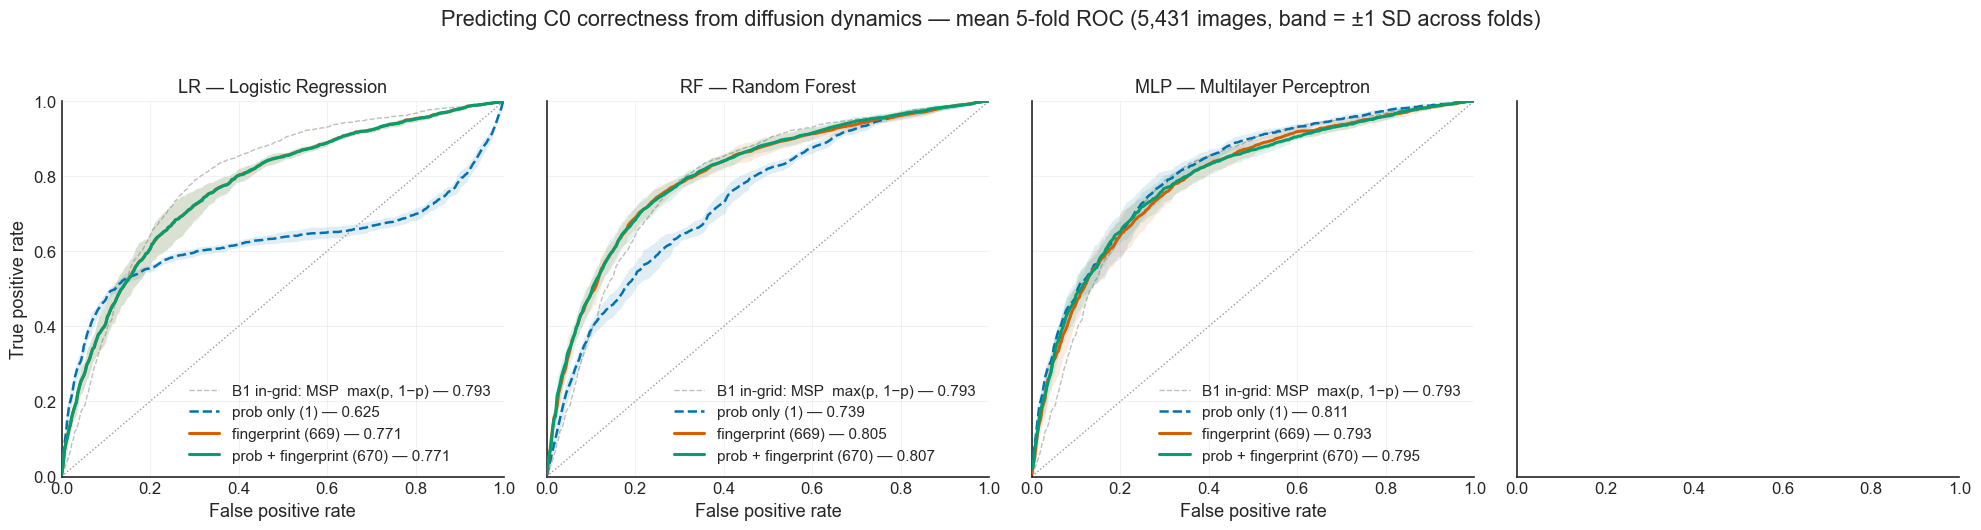

In [30]:
b1_roc = summarise([
    dict(zip(('fpr', 'tpr'),
             roc_curve(ref_y[oof_fold == i], B1_SCORE[oof_fold == i])[:2]),
         auc=roc_auc_score(ref_y[oof_fold == i], B1_SCORE[oof_fold == i]))
    for i in range(N_FOLDS)])

fig, axes = plt.subplots(1, 4, figsize=(20, 5.2), sharey=True)

for ax, model in zip(axes, MODELS):
    ax.plot(b1_roc['fpr'], b1_roc['tpr'], color=B1_COLOR, ls=B1_LS, lw=B1_LW,
            label=f'{B1_LABEL} — {b1_roc["auc"]:.3f}', zorder=1)
    for s in SETS:
        r = RUNS[(model, s)]
        ax.plot(r['fpr'], r['tpr'], color=SET_COLOR[s], ls=SET_LS[s], lw=SET_LW[s],
                label=f'{SET_LABELS[s]} — {r["auc"]:.3f}', zorder=3)
        ax.fill_between(r['fpr'], r['tpr'] - r['std'], r['tpr'] + r['std'],
                        color=SET_COLOR[s], alpha=0.12, lw=0, zorder=2)
    ax.plot([0, 1], [0, 1], color='#999999', ls=':', lw=1)
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='False positive rate',
           title=f'{model} — {MODEL_NAMES[model]}')
    ax.legend(loc='lower right', frameon=False)
    ax.grid(alpha=0.3)

axes[0].set_ylabel('True positive rate')
fig.suptitle('Predicting C0 correctness from diffusion dynamics — mean 5-fold ROC '
             f'({len(ref_y):,} images, band = ±1 SD across folds)', y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, 'diffusion_dynamics_roc_by_model.png'),
            dpi=200, bbox_inches='tight')
plt.show()

## 5. AUC Overview — Model × Feature Set

The headline table, then the same numbers as bars with per-fold points overlaid so the
spread sits next to the mean.

In [31]:
auc_tbl = (summary.pivot(index='feature_set', columns='model', values='mean_auc')
                  .reindex(index=SETS, columns=MODELS))
std_tbl = (summary.pivot(index='feature_set', columns='model', values='std_auc')
                  .reindex(index=SETS, columns=MODELS))

shown = auc_tbl.round(4).astype(str) + ' ± ' + std_tbl.round(4).astype(str)
shown.index = [SET_LABELS[s] for s in shown.index]
print('Mean 5-fold test AUC ± SD\n')
print(shown.to_string())
print(f'\nbest overall: {summary.iloc[0]["model"]} / {summary.iloc[0]["feature_set"]} '
      f'= {summary.iloc[0]["mean_auc"]:.4f}')
print(f'in-grid confidence baseline ({B1_NAME}): {B1_AUC:.4f}')

Mean 5-fold test AUC ± SD

model                                  LR               RF              MLP
prob only (1)             0.6253 ± 0.0087  0.7394 ± 0.0145  0.8112 ± 0.0139
fingerprint (669)          0.7711 ± 0.016  0.8053 ± 0.0127  0.7933 ± 0.0202
prob + fingerprint (670)  0.7709 ± 0.0162   0.8073 ± 0.013  0.7953 ± 0.0192

best overall: MLP / prob_only = 0.8112
in-grid confidence baseline (MSP  max(p, 1−p)): 0.7927


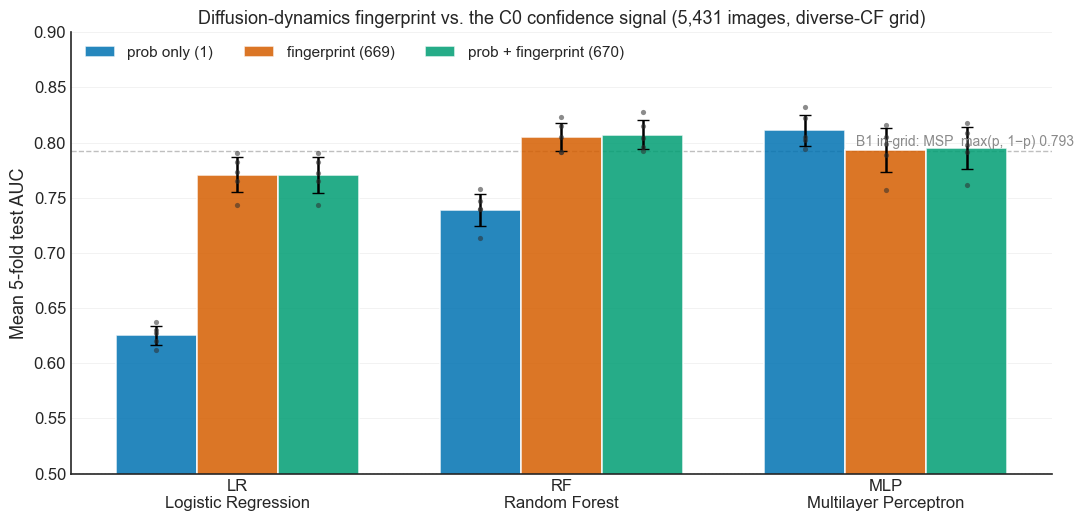

In [32]:
fig, ax = plt.subplots(figsize=(11, 5.4))
w, x = 0.25, np.arange(len(MODELS))

for i, s in enumerate(SETS):
    means = [RUNS[(m, s)]['auc'] for m in MODELS]
    errs  = [RUNS[(m, s)]['auc_std'] for m in MODELS]
    pos   = x + (i - 1) * w
    ax.bar(pos, means, w, yerr=errs, capsize=4, color=SET_COLOR[s],
           alpha=0.85, edgecolor='white', linewidth=1.2, label=SET_LABELS[s], zorder=2)
    for p, m in zip(pos, MODELS):                      # per-fold points
        ax.scatter(np.full(N_FOLDS, p), RUNS[(m, s)]['aucs'], s=14, color='#2D2D2D',
                   alpha=0.55, zorder=4, linewidths=0)

ax.axhline(B1_AUC, color=B1_COLOR, ls=B1_LS, lw=B1_LW, zorder=1)
ax.text(len(MODELS) - 0.42, B1_AUC + 0.004, f'{B1_LABEL} {B1_AUC:.3f}',
        color='#8A8A8A', fontsize=10, ha='right')

ax.axhline(0.5, color='#999999', ls=':', lw=1, zorder=1)

ax.set(xticks=x, ylim=(0.5, 0.90), ylabel='Mean 5-fold test AUC',
       title='Diffusion-dynamics fingerprint vs. the C0 confidence signal '
             f'({len(ref_y):,} images, diverse-CF grid)')
ax.set_xticklabels([f'{m}\n{MODEL_NAMES[m]}' for m in MODELS])
ax.legend(frameon=False, ncol=3, loc='upper left')
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, 'diffusion_dynamics_auc_bars.png'),
            dpi=200, bbox_inches='tight')
plt.show()

## 8. Does the Fingerprint Help Where Confidence Fails?

A failure detector that only re-derives C0 confidence is redundant. The question that
matters is whether the dynamics carry signal **inside** a confidence band, where `p` has
almost no variance left to exploit.

Images are binned into quartiles of the confidence margin |p − τ|, and AUC is recomputed
within each bin. `prob_only` and the training-free baseline should both collapse toward 0.5
in the narrow bins by construction; anything the fingerprint retains there is genuinely new.